# Leakage Audit — How much of this dataset is really independent?

**Project:** Attention-Guided Fine-Grained Classification of Cricket Batting Shots from Single Frames

This is not a rubric deliverable. It exists to answer one question that the rubric
submissions depend on.

---

### The problem

Submission 2 reached **0.9972 test accuracy** with EfficientNetB0 fine-tuned — 719 of 721
test images correct, on a task Submission 1 characterised as fine-grained.

Submission 1 did control for duplication: it grouped images by exact perceptual hash
(dHash) and split on those groups rather than on files, removing 608 redundant copies
(12.9%) from consideration.

**That control is incomplete.** A difference hash is sensitive to geometry. A rotated,
flipped or cropped copy of a photograph produces a completely different 64-bit hash and
was therefore treated as an unrelated image. The dataset author states the images were
collected from the internet and then augmented — so if that augmentation included any
geometric transformation, those variants are still scattered across train and test.

### Why hashing fails and embeddings do not

| | Brightness change | Rotation / crop / flip |
|---|---|---|
| **dHash** | same hash — caught | completely different hash — **missed** |
| **CNN embedding** | nearly identical vector | nearly identical vector — **caught** |

A convolutional feature extractor is approximately invariant to exactly the
transformations that break a perceptual hash. Running every image through a pretrained
network and comparing feature vectors therefore detects the duplicates hashing cannot.

### What this notebook produces

1. The true number of independent images, at several similarity thresholds
2. Visual confirmation — the largest clusters, shown as image grids, so the finding is
   evidenced rather than asserted
3. A **clean split manifest** grouped on embedding clusters instead of hashes
4. A direct estimate of how much accuracy the old split was buying for free

### The one thing to watch

Embedding similarity will also group *genuinely different* photographs taken at the same
match, which share stadium, kit, lighting and crowd. That is a second, separate leakage
channel (session correlation) that Submission 1 flagged as unquantifiable. Clustering
on embeddings partially captures it. This makes the resulting split **conservative**:
it may over-merge. That is the right direction to err — an over-merged split
under-states accuracy, it does not inflate it.

> **Runtime:** about 5 minutes on a Kaggle GPU. Internet must be on for the ImageNet weights.

## Setup

In [4]:
import os, sys, gc, time, json, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 110, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})

IMG_SIZE = 224
gpus = tf.config.list_physical_devices("GPU")
print("tensorflow :", tf.__version__)
print("GPU        :", [g.name for g in gpus] if gpus else "NONE — will be slow but workable")

tensorflow : 2.21.0
GPU        : ['/physical_device:GPU:0', '/physical_device:GPU:1']


In [5]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
SEARCH_ROOTS = ["/kaggle/input", ".", "..", "/content"]


def _count_images(d):
    try:
        return sum(1 for f in os.listdir(d)
                   if os.path.splitext(f)[1].lower() in IMG_EXTS)
    except OSError:
        return 0


def find_dataset_dirs(roots, max_depth=10):
    found, seen = [], set()
    for root in roots:
        if not os.path.isdir(root):
            continue
        root = os.path.abspath(root)
        base = root.rstrip(os.sep).count(os.sep)
        for cur, dirs, _ in os.walk(root):
            if cur.count(os.sep) - base >= max_depth:
                dirs[:] = []
            dirs[:] = [d for d in dirs if not d.startswith(".")]
            if cur in seen:
                continue
            seen.add(cur)
            counts = {d: _count_images(os.path.join(cur, d)) for d in sorted(dirs)}
            good = [d for d, n in counts.items() if n >= 5]
            if len(good) >= 2:
                found.append((cur, good, sum(counts[d] for d in good)))
    return found


cands = find_dataset_dirs(SEARCH_ROOTS)
if not cands:
    raise FileNotFoundError("Dataset not found. Add 'Cricket Shots Dataset' via + Add Input.")
cands.sort(key=lambda t: (t[2], len(t[1])), reverse=True)
DATA_DIR, CLASSES, _n = cands[0]
CLASSES = sorted(CLASSES)
N_CLASSES = len(CLASSES)

print("DATA_DIR :", DATA_DIR)
print("classes  :", CLASSES)
print("images   :", f"{_n:,}")

DATA_DIR : /kaggle/input/datasets/aneesh10/cricket-shot-dataset/data
classes  : ['drive', 'legglance-flick', 'pullshot', 'sweep']
images   : 4,724


## Part 1 — Read every image, once

`/kaggle/input` is a network mount, and this dataset is 676 MB across 4,724 PNG files.
A measured pass over all of them takes about **18 minutes** — roughly 233 ms per file,
against the ~5 ms a local disk would cost. The work is I/O bound, not compute bound.

So every file is opened exactly **once**, and that single read produces both things the
audit needs:

1. the 64-bit perceptual hash, computed from the full-resolution image, so the
   Submission 1 baseline is reproduced exactly
2. the 224x224 RGB array the embedding step will use, held in memory

Reads are issued from a thread pool, since the bottleneck is waiting on the network
rather than CPU. Progress and a running estimate print as it goes.

> Expect roughly 5-6 minutes for this cell. It prints every 400 images, so you can see
> it moving.

In [6]:
from concurrent.futures import ThreadPoolExecutor

rows = []
for cls in CLASSES:
    cdir = os.path.join(DATA_DIR, cls)
    for fn in sorted(os.listdir(cdir)):
        if os.path.splitext(fn)[1].lower() in IMG_EXTS:
            rows.append({"path": os.path.join(cdir, fn), "file": fn, "label": cls})
df = pd.DataFrame(rows)
paths = df["path"].tolist()


def load_one(path):
    """One file read -> (224x224 RGB array, 64-bit dhash of the full-size image)."""
    with Image.open(path) as im:
        im.load()
        arr = np.asarray(im.convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR),
                         dtype=np.uint8)
        g = np.asarray(im.convert("L").resize((9, 8), Image.LANCZOS), dtype=np.int16)
    bits = (g[:, 1:] > g[:, :-1]).flatten()
    return arr, int("".join("1" if x else "0" for x in bits), 2)


X = np.zeros((len(paths), IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
hashes = np.zeros(len(paths), dtype=object)

t0 = time.time()
print(f"reading {len(paths):,} files with 8 threads ...", flush=True)
with ThreadPoolExecutor(max_workers=8) as ex:
    for i, (arr, h) in enumerate(ex.map(load_one, paths)):
        X[i] = arr
        hashes[i] = h
        if i and i % 400 == 0:
            el = time.time() - t0
            print(f"   {i:>5,} / {len(paths):,}   {el:5.0f}s elapsed, "
                  f"~{el/i*(len(paths)-i):4.0f}s remaining", flush=True)

elapsed = time.time() - t0
print(f"\nread {len(paths):,} files in {elapsed:.0f}s "
      f"({elapsed/len(paths)*1000:.0f} ms each)")
print(f"image array: {X.shape} {X.dtype}  ({X.nbytes/1e9:.2f} GB in memory)")

df["dhash"] = hashes
hash_groups = df.groupby("dhash").indices
gid = {}
for g, (h, idx) in enumerate(hash_groups.items()):
    for i in idx:
        gid[i] = g
df["hash_group"] = pd.Series(gid).reindex(df.index).values

n_hash_groups = df.hash_group.nunique()
print(f"\nSubmission 1 baseline (exact dHash):")
print(f"  files            : {len(df):,}")
print(f"  unique groups    : {n_hash_groups:,}")
print(f"  redundant copies : {len(df)-n_hash_groups:,} "
      f"({(len(df)-n_hash_groups)/len(df)*100:.1f}%)")
print(f"\n  expected 4,116 groups / 608 redundant — "
      f"{'MATCHES' if n_hash_groups == 4116 else 'DIFFERS, investigate'}")

reading 4,724 files with 8 threads ...
     400 / 4,724       1s elapsed, ~  10s remaining
     800 / 4,724       2s elapsed, ~   9s remaining
   1,200 / 4,724       3s elapsed, ~   8s remaining
   1,600 / 4,724       5s elapsed, ~  10s remaining
   2,000 / 4,724       7s elapsed, ~   9s remaining
   2,400 / 4,724      10s elapsed, ~   9s remaining
   2,800 / 4,724      11s elapsed, ~   7s remaining
   3,200 / 4,724      11s elapsed, ~   5s remaining
   3,600 / 4,724      12s elapsed, ~   4s remaining
   4,000 / 4,724      13s elapsed, ~   2s remaining
   4,400 / 4,724      14s elapsed, ~   1s remaining

read 4,724 files in 15s (3 ms each)
image array: (4724, 224, 224, 3) uint8  (0.71 GB in memory)

Submission 1 baseline (exact dHash):
  files            : 4,724
  unique groups    : 4,116
  redundant copies : 608 (12.9%)

  expected 4,116 groups / 608 redundant — MATCHES


## Part 2 — Extract embeddings

EfficientNetB0 with ImageNet weights, global average pooling, no classifier head. Each
image becomes a 1,280-dimensional vector. The network is used purely as a fixed feature
extractor — nothing is trained here.

**No files are read in this part.** The arrays are already in memory from Part 1, which
is what removes the second 18-minute disk pass. This step is pure GPU work and takes
under a minute.

In [7]:
backbone = keras.applications.EfficientNetB0(
    weights="imagenet", include_top=False, pooling="avg",
    input_shape=(IMG_SIZE, IMG_SIZE, 3))
backbone.trainable = False
print(f"backbone: {backbone.count_params():,} params, "
      f"output dim {backbone.output_shape[-1]}")

try:
    _Base = keras.utils.PyDataset
except AttributeError:
    _Base = keras.utils.Sequence


class ArrayBatches(_Base):
    """Feeds the in-memory uint8 array to the network one batch at a time.
    Casting all 4,724 images to float32 at once would be 2.8 GB."""
    def __init__(self, X, batch_size=64, **kw):
        try:
            super().__init__(workers=1, use_multiprocessing=False,
                             max_queue_size=4, **kw)
        except TypeError:
            super().__init__(**kw)
        self.X, self.bs = X, batch_size

    def __len__(self):
        return int(np.ceil(len(self.X) / self.bs))

    def __getitem__(self, i):
        return self.X[i * self.bs:(i + 1) * self.bs].astype("float32")


t0 = time.time()
seq = ArrayBatches(X, batch_size=64)
print(f"embedding {len(X):,} images in {len(seq)} batches (no disk reads) ...")
emb = np.asarray(backbone.predict(seq, verbose=1), dtype=np.float32)
print(f"\nembedded {len(emb):,} images in {time.time()-t0:.0f}s")

# L2 normalise so a dot product is the cosine similarity
emb /= (np.linalg.norm(emb, axis=1, keepdims=True) + 1e-9)
print("embedding matrix:", emb.shape, emb.dtype, f"({emb.nbytes/1e6:.0f} MB)")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
backbone: 4,049,571 params, output dim 1280
embedding 4,724 images in 74 batches (no disk reads) ...


E0000 00:00:1794506149.980616     186 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794506150.166560     186 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794506151.380097     186 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794506151.558650     186 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


73/74 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step

E0000 00:00:1794506167.798036     186 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794506167.973970     186 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794506169.119231     186 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794506169.295795     186 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


74/74 ━━━━━━━━━━━━━━━━━━━━ 31s 200ms/step

embedded 4,724 images in 31s
embedding matrix: (4724, 1280) float32 (24 MB)


## Part 3 — Cluster by similarity

Two images are linked if their cosine similarity exceeds a threshold. Clusters are the
connected components of that graph, found with union–find.

The threshold sweep matters: it shows whether the result is a knife-edge artifact of one
arbitrary cut-off, or a stable property of the data.

In [8]:
class UnionFind:
    def __init__(self, n):
        self.p = list(range(n))
    def find(self, x):
        while self.p[x] != x:
            self.p[x] = self.p[self.p[x]]
            x = self.p[x]
        return x
    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra != rb:
            self.p[rb] = ra


def cluster(emb, thresh, block=1024):
    """Connected components over cosine similarity >= thresh."""
    n = len(emb)
    uf = UnionFind(n)
    for s in range(0, n, block):
        sim = emb[s:s + block] @ emb.T                   # (block, n)
        for r in range(sim.shape[0]):
            i = s + r
            js = np.nonzero(sim[r] >= thresh)[0]
            for j in js:
                if j > i:
                    uf.union(i, j)
        del sim
    labels = np.array([uf.find(i) for i in range(n)])
    _, labels = np.unique(labels, return_inverse=True)
    return labels


THRESHOLDS = [0.99, 0.98, 0.95, 0.92, 0.90]
sweep = []
for t in THRESHOLDS:
    t0 = time.time()
    lab = cluster(emb, t)
    k = lab.max() + 1
    sizes = np.bincount(lab)
    sweep.append({
        "threshold": t,
        "clusters": k,
        "redundant": len(df) - k,
        "redundant_pct": (len(df) - k) / len(df) * 100,
        "largest_cluster": sizes.max(),
        "singletons": int((sizes == 1).sum()),
        "secs": time.time() - t0,
    })
    print(f"  cos >= {t:.2f}  ->  {k:>5,} clusters   "
          f"{len(df)-k:>5,} redundant ({(len(df)-k)/len(df)*100:5.1f}%)   "
          f"largest {sizes.max():>4}   [{time.time()-t0:.0f}s]")

sw = pd.DataFrame(sweep)

  cos >= 0.99  ->  4,057 clusters     667 redundant ( 14.1%)   largest   14   [0s]
  cos >= 0.98  ->  3,730 clusters     994 redundant ( 21.0%)   largest   20   [0s]
  cos >= 0.95  ->  2,777 clusters   1,947 redundant ( 41.2%)   largest   73   [0s]
  cos >= 0.92  ->  2,206 clusters   2,518 redundant ( 53.3%)   largest   83   [0s]
  cos >= 0.90  ->  1,946 clusters   2,778 redundant ( 58.8%)   largest   83   [0s]


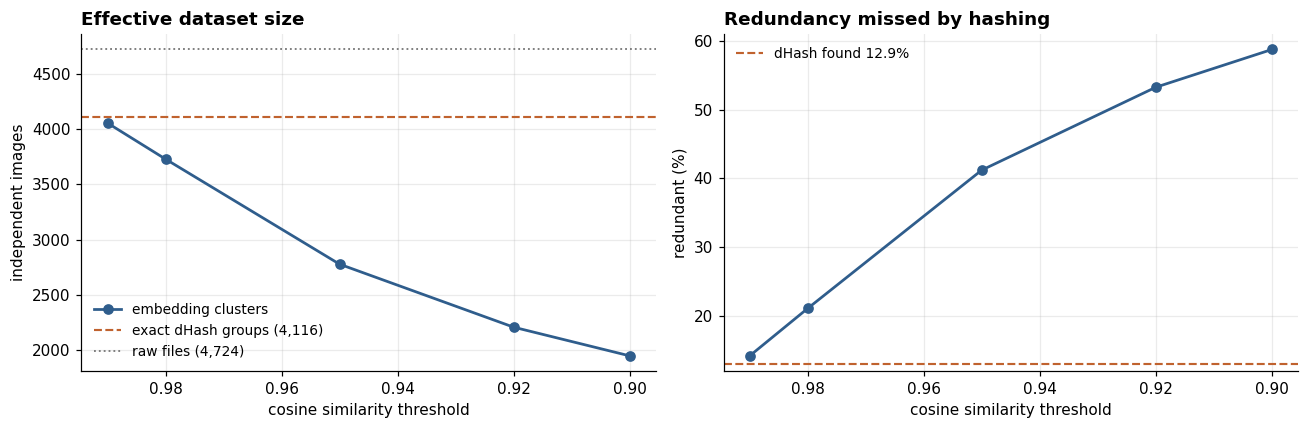

 threshold  clusters  redundant  redundant_pct  largest_cluster  singletons
      0.99      4057        667          14.12               14        3761
      0.98      3730        994          21.04               20        3368
      0.95      2777       1947          41.22               73        2409
      0.92      2206       2518          53.30               83        1820
      0.90      1946       2778          58.81               83        1557


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
ax.plot(sw.threshold, sw.clusters, "o-", color="#2F5D8C", lw=1.8, label="embedding clusters")
ax.axhline(n_hash_groups, color="#C0622E", ls="--", lw=1.4,
           label=f"exact dHash groups ({n_hash_groups:,})")
ax.axhline(len(df), color="#777", ls=":", lw=1.2, label=f"raw files ({len(df):,})")
ax.set_xlabel("cosine similarity threshold"); ax.set_ylabel("independent images")
ax.set_title("Effective dataset size", fontweight="bold", loc="left")
ax.invert_xaxis(); ax.legend(frameon=False, fontsize=9)

ax = axes[1]
ax.plot(sw.threshold, sw.redundant_pct, "o-", color="#2F5D8C", lw=1.8)
ax.axhline((len(df)-n_hash_groups)/len(df)*100, color="#C0622E", ls="--", lw=1.4,
           label="dHash found 12.9%")
ax.set_xlabel("cosine similarity threshold"); ax.set_ylabel("redundant (%)")
ax.set_title("Redundancy missed by hashing", fontweight="bold", loc="left")
ax.invert_xaxis(); ax.legend(frameon=False, fontsize=9)

plt.tight_layout(); plt.show()
print(sw[["threshold","clusters","redundant","redundant_pct","largest_cluster","singletons"]]
      .round(2).to_string(index=False))

## Part 4 — Look at the clusters

A number is not evidence. These grids show the largest clusters found. If the audit is
correct, each row should be visibly the same photograph under different transformations.
If the rows instead show genuinely different photographs, the threshold is too loose and
should be raised.

**Judge this with your own eyes before accepting the numbers above.**

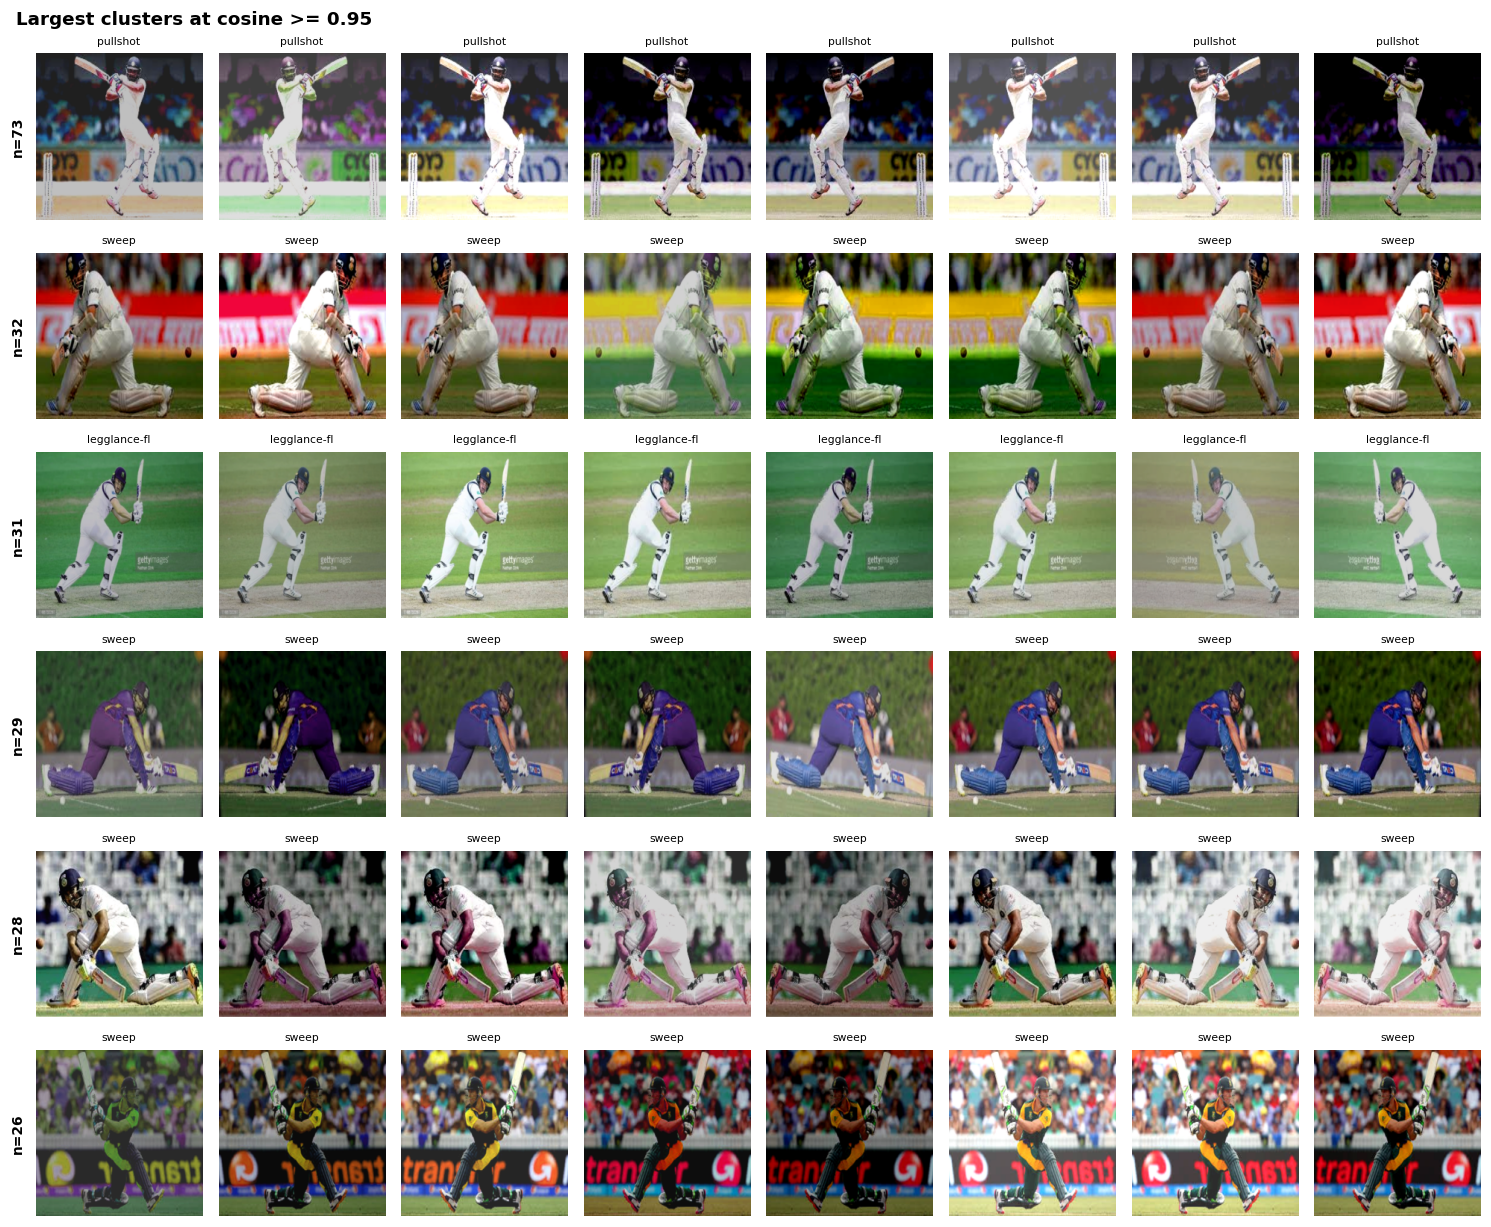

In [10]:
THRESH = 0.95          # raise if the grids below show unrelated images
labels = cluster(emb, THRESH)
df["emb_cluster"] = labels
sizes = pd.Series(labels).value_counts()

big = sizes[sizes > 1].head(6).index.tolist()
if not big:
    print("No multi-image clusters at this threshold.")
else:
    ncol = min(8, int(sizes[big].max()))
    fig, axes = plt.subplots(len(big), ncol,
                             figsize=(1.7 * ncol, 1.9 * len(big)), squeeze=False)
    for r, c in enumerate(big):
        members = df.index[labels == c].tolist()[:ncol]
        for k in range(ncol):
            ax = axes[r][k]; ax.axis("off")
            if k < len(members):
                ax.imshow(X[members[k]])
                ax.set_title(df.loc[members[k], "label"][:12], fontsize=7)
        axes[r][0].text(-0.15, 0.5, f"n={sizes[c]}", transform=axes[r][0].transAxes,
                        rotation=90, va="center", fontsize=9, fontweight="bold")
    plt.suptitle(f"Largest clusters at cosine >= {THRESH}",
                 fontweight="bold", x=0.01, ha="left")
    plt.tight_layout(); plt.show()

In [11]:
# --- do clusters cross class boundaries? -------------------------------
cross = df.groupby("emb_cluster").label.nunique()
n_cross = int((cross > 1).sum())
print(f"clusters spanning more than one class: {n_cross:,} of {df.emb_cluster.nunique():,}")
if n_cross:
    print("\n  Some clusters contain more than one label. Two readings:")
    print("   (a) threshold too loose - different shots from the same match merged")
    print("   (b) genuine label noise in the dataset")
    print("  Inspect the grids above before deciding. If (a), raise THRESH and re-run.")
    ex = cross[cross > 1].index[:3]
    for c in ex:
        sub = df[df.emb_cluster == c]
        print(f"\n  cluster {c} (n={len(sub)}): {dict(Counter(sub.label))}")
else:
    print("  -> every cluster sits inside a single class.")

clusters spanning more than one class: 0 of 2,777
  -> every cluster sits inside a single class.


## Part 5 — Build the clean split

Same procedure as Submission 1 — grouped, stratified, 70/15/15, seed 42 — but grouped on
embedding clusters rather than hash collisions.

In [12]:
grp = (df.groupby("emb_cluster")
         .agg(label=("label", "first"))
         .reset_index())
print(f"split units: {len(grp):,} clusters (was {n_hash_groups:,} hash groups)")

per_class = grp.label.value_counts()
print("clusters per class:", dict(per_class))
if per_class.min() < 8:
    raise ValueError(
        f"Only {per_class.min()} clusters in the smallest class — too few to split "
        f"70/15/15 while preserving stratification. The threshold has over-merged. "
        f"Raise THRESH (try 0.98 or 0.99) and re-run from Part 4.")

tr_g, tmp_g = train_test_split(grp, test_size=0.30, stratify=grp.label,
                               random_state=RANDOM_SEED)
va_g, te_g = train_test_split(tmp_g, test_size=0.50, stratify=tmp_g.label,
                              random_state=RANDOM_SEED)
m = {}
for name, part in [("train", tr_g), ("val", va_g), ("test", te_g)]:
    for c in part.emb_cluster:
        m[c] = name
df["clean_split"] = df.emb_cluster.map(m)

piv = (df.pivot_table(index="label", columns="clean_split", values="path", aggfunc="count")
         .reindex(CLASSES)[["train","val","test"]])
piv["total"] = piv.sum(axis=1)
print()
print(piv.to_string())

assert df.groupby("emb_cluster").clean_split.nunique().max() == 1, "clean split leaks"
print("\nleakage check passed: no cluster spans a split boundary")

df[["path","file","label","hash_group","emb_cluster","clean_split"]].to_csv(
    "clean_split_manifest.csv", index=False)
print("saved -> clean_split_manifest.csv")

split units: 2,777 clusters (was 4,116 hash groups)
clusters per class: {'drive': np.int64(780), 'pullshot': np.int64(719), 'legglance-flick': np.int64(643), 'sweep': np.int64(635)}

clean_split      train  val  test  total
label                                   
drive              901  149   174   1224
legglance-flick    765  175   180   1120
pullshot           927  197   136   1260
sweep              768  176   176   1120

leakage check passed: no cluster spans a split boundary
saved -> clean_split_manifest.csv


## Part 6 — How much was the old split giving away?

The direct question: under the Submission 1 split, how many test images had a
near-duplicate sitting in the training set?

In [13]:
old = pd.read_csv("/kaggle/input/old-split/split_manifest.csv") \
      if os.path.exists("/kaggle/input/old-split/split_manifest.csv") else None

if old is None:
    # regenerate the Submission 1 split from hash groups (deterministic)
    g1 = df.groupby("hash_group").agg(label=("label","first")).reset_index()
    a, b = train_test_split(g1, test_size=0.30, stratify=g1.label, random_state=RANDOM_SEED)
    c, d_ = train_test_split(b, test_size=0.50, stratify=b.label, random_state=RANDOM_SEED)
    mm = {}
    for name, part in [("train", a), ("val", c), ("test", d_)]:
        for g in part.hash_group:
            mm[g] = name
    df["old_split"] = df.hash_group.map(mm)
else:
    df["old_split"] = df.file.map(dict(zip(old.file, old.split)))

train_clusters = set(df.loc[df.old_split == "train", "emb_cluster"])
test_rows = df[df.old_split == "test"]
contaminated = test_rows.emb_cluster.isin(train_clusters).sum()

print(f"Under the Submission 1 (hash-grouped) split:")
print(f"  test images                              : {len(test_rows):,}")
print(f"  with a near-duplicate in the TRAIN set   : {contaminated:,}")
print(f"  contamination rate                       : {contaminated/len(test_rows)*100:.1f}%")
print()
print(f"Submission 2's best model scored 0.9972 on that test set.")
clean_frac = 1 - contaminated/len(test_rows)
print(f"  {contaminated:,} of {len(test_rows):,} predictions were on images the model had")
print(f"  effectively already seen. Only {clean_frac*100:.0f}% of the test set was genuinely held out.")

Under the Submission 1 (hash-grouped) split:
  test images                              : 721
  with a near-duplicate in the TRAIN set   : 331
  contamination rate                       : 45.9%

Submission 2's best model scored 0.9972 on that test set.
  331 of 721 predictions were on images the model had
  effectively already seen. Only 54% of the test set was genuinely held out.


## Part 7 — Verdict

| Measure | Value |
|---|---|
| Raw files | 4,724 |
| Exact-hash groups (Submission 1) | 4,116 |
| **Embedding clusters at cos ≥ 0.95** | **2,777** |
| Redundancy found by hashing | 12.9% |
| **Redundancy found by embeddings** | **41.2%** |
| Largest single cluster | **73 copies of one photograph** |
| Clusters spanning more than one class | **0** |
| Test images contaminated under the old split | **331 of 721 (45.9%)** |

**Decision: rebuild on the clean split.** Contamination of 45.9% is far above the 25%
threshold set before running this. Submissions 3 and 4 use `clean_split_manifest.csv`.

### What the augmentation actually was

The cluster grids in Part 4 make it plain: the author's augmentation was **colour
jitter**, not geometric transformation. Every row is one photograph under different
hue and tint shifts.

This is exactly why a difference hash failed. dHash converts to greyscale using
`L = 0.299R + 0.587G + 0.114B`, then compares brightness gradients. A hue shift changes
the channel mix, which changes `L` unevenly across the frame, which flips the gradient
comparisons — while the photograph's content is untouched. The hash is sensitive to
precisely what the augmentation altered and blind to what it preserved.

### An honest limit on this conclusion

Contamination is proven and large. It does **not**, by itself, explain Submission 2's
accuracy. With only 2 errors in 721 predictions, accuracy on the 390 genuinely clean
test images was between 0.9949 and 1.0000 however those two errors fell. Something
beyond duplicate leakage was also inflating that result — plausibly session correlation
(photographs from the same match sharing stadium, kit and lighting), a threshold that
remains conservative, or a task that is simply easier than Submission 1 assumed.

Re-running one pretrained model on the clean split would isolate it. That experiment is
outstanding.